In [10]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
%matplotlib inline
plt.rcParams['figure.figsize'] = (16, 9)
plt.style.use('fast')

from keras.models import Sequential
from keras.layers import Dense,Activation,Flatten
from sklearn.preprocessing import MinMaxScaler

df = pd.read_csv('time_series.csv', parse_dates=[0], header=None, index_col=0, names=['fecha', 'unidades'])
df.head()

,unidades
fecha,
2017-01-02,236
2017-01-03,237
2017-01-04,290
2017-01-05,221
2017-01-07,128


In [11]:
print(df.index.min())
print(df.index.max())

2017-01-02 00:00:00
2018-11-30 00:00:00


In [13]:
# Verificar que el índice sea de tipo fecha
print(type(df.index))

# Contar cuántos datos hay en 2017 y 2018
print("Datos de 2017:", len(df.loc['2017']))
print("Datos de 2018:", len(df.loc['2018']))

<class 'pandas.DatetimeIndex'>
Datos de 2017: 315
Datos de 2018: 289


In [14]:
df.describe()

,unidades
count,604.000000
mean,215.935430
std,75.050304
min,51.000000
25%,171.000000
50%,214.000000
75%,261.250000
max,591.000000


In [16]:
meses = df.resample('ME').mean()
meses

,unidades
fecha,
2017-01-31,203.923077
2017-02-28,184.666667
2017-03-31,182.964286
2017-04-30,198.960000
2017-05-31,201.185185
2017-06-30,209.518519
2017-07-31,278.923077
2017-08-31,316.000000
2017-09-30,222.925926


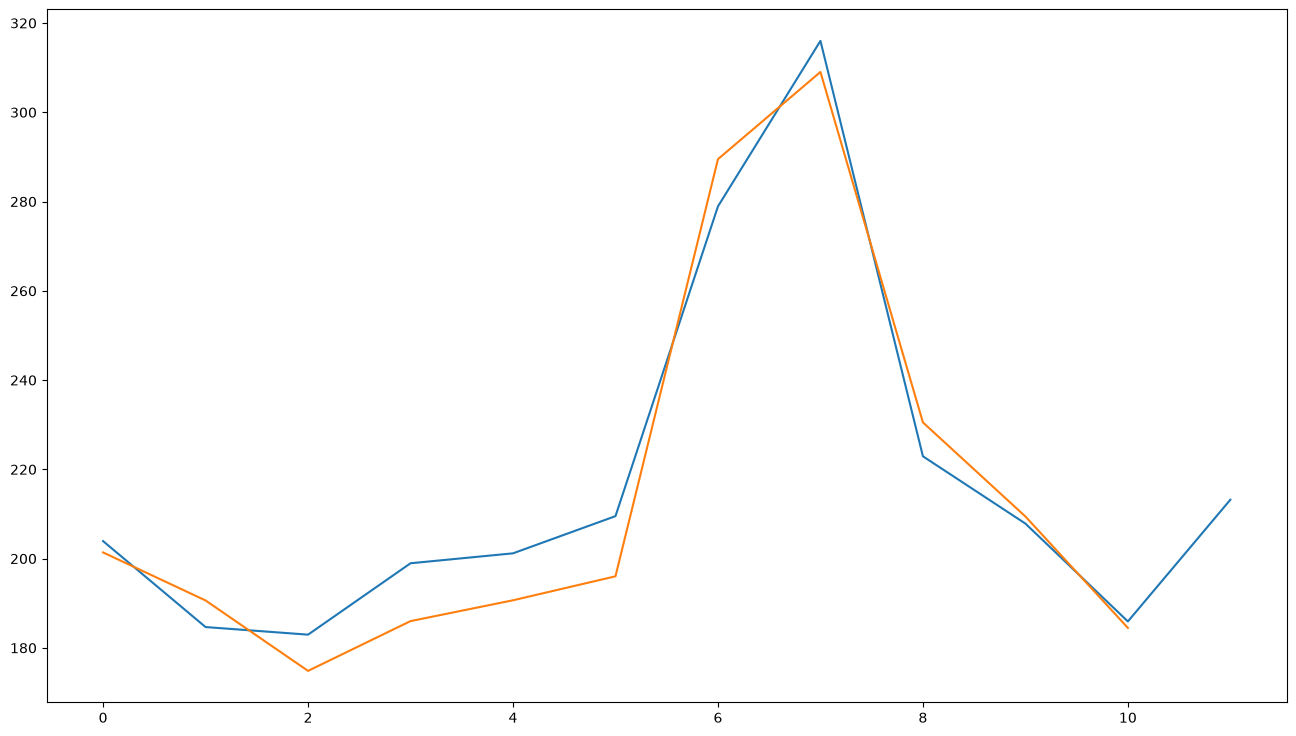

In [18]:
plt.plot(meses.loc['2017'].values)
plt.plot(meses.loc['2018'].values)

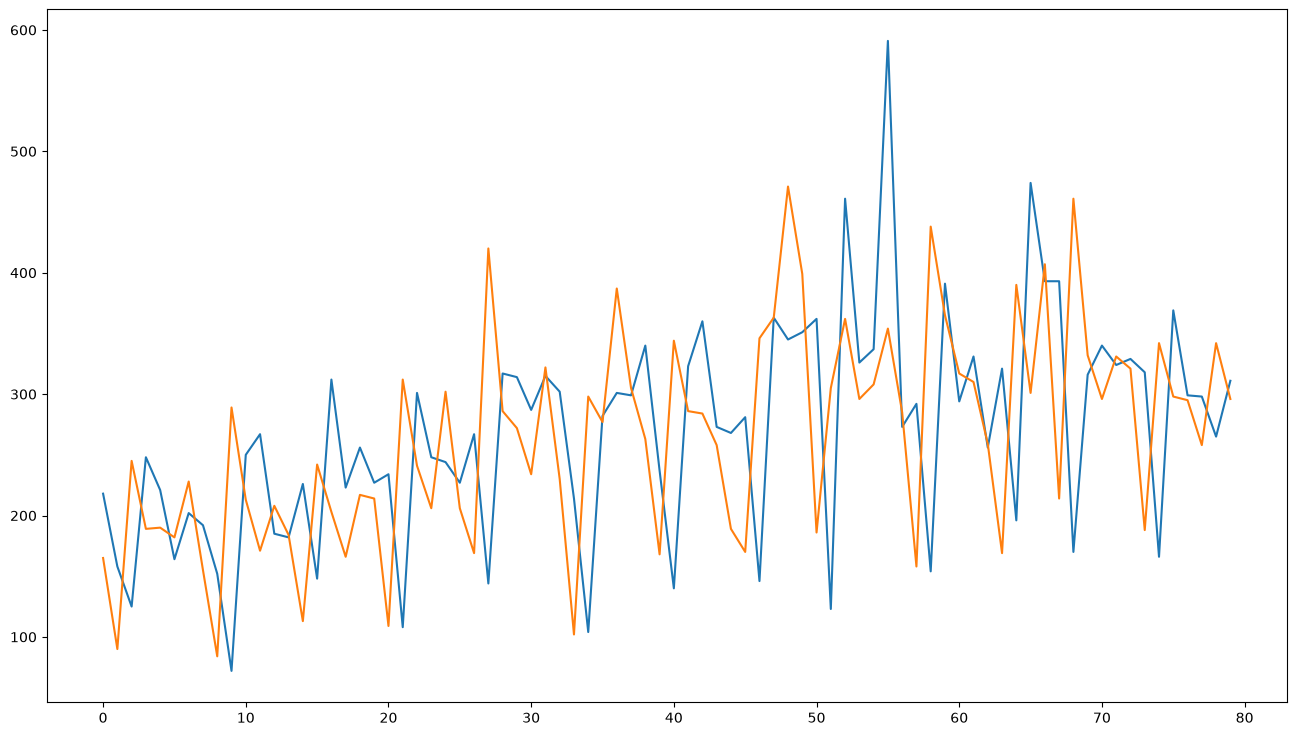

In [20]:
verano2017 = df['2017-06-01':'2017-09-01']
plt.plot(verano2017.values)
verano2018 = df['2018-06-01':'2018-09-01']
plt.plot(verano2018.values)

In [22]:
PASOS=7

# convert series to supervised learning
def series_to_supervised(data, n_in=1, n_out=1, dropnan=True):
    n_vars = 1 if type(data) is list else data.shape[1]
    df = pd.DataFrame(data)
    cols, names = list(), list()
    # input sequence (t-n, ... t-1)
    for i in range(n_in, 0, -1):
        cols.append(df.shift(i))
        names += [('var%d(t-%d)' % (j+1, i)) for j in range(n_vars)]
    # forecast sequence (t, t+1, ... t+n)
    for i in range(0, n_out):
        cols.append(df.shift(-i))
        if i == 0:
            names += [('var%d(t)' % (j+1)) for j in range(n_vars)]
        else:
            names += [('var%d(t+%d)' % (j+1, i)) for j in range(n_vars)]
    # put it all together
    agg = pd.concat(cols, axis=1)
    agg.columns = names
    # drop rows with NaN values
    if dropnan:
        agg.dropna(inplace=True)
    return agg
 
# load dataset
values = df.values
# ensure all data is float
values = values.astype('float32')
# normalize features
scaler = MinMaxScaler(feature_range=(-1, 1))
values=values.reshape(-1, 1) # esto lo hacemos porque tenemos 1 sola dimension
scaled = scaler.fit_transform(values)
# frame as supervised learning
reframed = series_to_supervised(scaled, PASOS, 1)
reframed.head()

,var1(t-7),var1(t-6),var1(t-5),var1(t-4),var1(t-3),var1(t-2),var1(t-1),var1(t)
7,-0.314815,-0.311111,-0.114815,-0.370370,-0.714815,-0.103704,-0.225926,-0.433333
8,-0.311111,-0.114815,-0.370370,-0.714815,-0.103704,-0.225926,-0.433333,-0.607407
9,-0.114815,-0.370370,-0.714815,-0.103704,-0.225926,-0.433333,-0.607407,-0.522222
10,-0.370370,-0.714815,-0.103704,-0.225926,-0.433333,-0.607407,-0.522222,-0.644444
11,-0.714815,-0.103704,-0.225926,-0.433333,-0.607407,-0.522222,-0.644444,-0.344444


Creamos la Red Neuronal Artificial

In [24]:
values = reframed.values
n_train_days = 315+289 - (30+PASOS)
train = values[:n_train_days, :]
test = values[n_train_days:, :]
# split into input and outputs
x_train, y_train = train[:, :-1], train[:, -1]
x_val, y_val = test[:, :-1], test[:, -1]
# reshape input to be 3D [samples, timesteps, features]
x_train = x_train.reshape((x_train.shape[0], 1, x_train.shape[1]))
x_val = x_val.reshape((x_val.shape[0], 1, x_val.shape[1]))
print(x_train.shape, y_train.shape, x_val.shape, y_val.shape)

(567, 1, 7) (567,) (30, 1, 7) (30,)


In [25]:
def crear_modeloFF():
    model = Sequential() 
    model.add(Dense(PASOS, input_shape=(1,PASOS),activation='tanh'))
    model.add(Flatten())
    model.add(Dense(1, activation='tanh'))
    model.compile(loss='mean_absolute_error',optimizer='Adam',metrics=["mse"])
    model.summary()
    return model

Entrenamiento y Resultados

In [26]:
EPOCHS=40

model = crear_modeloFF()

history=model.fit(x_train,y_train,epochs=EPOCHS,validation_data=(x_val,y_val),batch_size=PASOS)

d:\Datos\tensorflow\tf-env-312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1, 7)           │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64 (256.00 B)

 Trainable params: 64 (256.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.2625 - mse: 0.1170 - val_loss: 0.2152 - val_mse: 0.0757
Epoch 2/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2284 - mse: 0.0901 - val_loss: 0.1988 - val_mse: 0.0634
Epoch 3/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2139 - mse: 0.0793 - val_loss: 0.1881 - val_mse: 0.0579
Epoch 4/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2025 - mse: 0.0724 - val_loss: 0.1784 - val_mse: 0.0534
Epoch 5/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1934 - mse: 0.0683 - val_loss: 0.1714 - val_mse: 0.0483
Epoch 6/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1866 - mse: 0.0638 - val_loss: 0.1651 - val_mse: 0.0484
Epoch 7/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1831 - mse: 0.0611 - val_loss: 0.1614 - val_mse: 0.0459
Epoch 8/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1804 - mse: 0.0601 - val_loss: 0.1579 - val_mse: 0.0436
Epoch 9/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1774 - mse: 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step


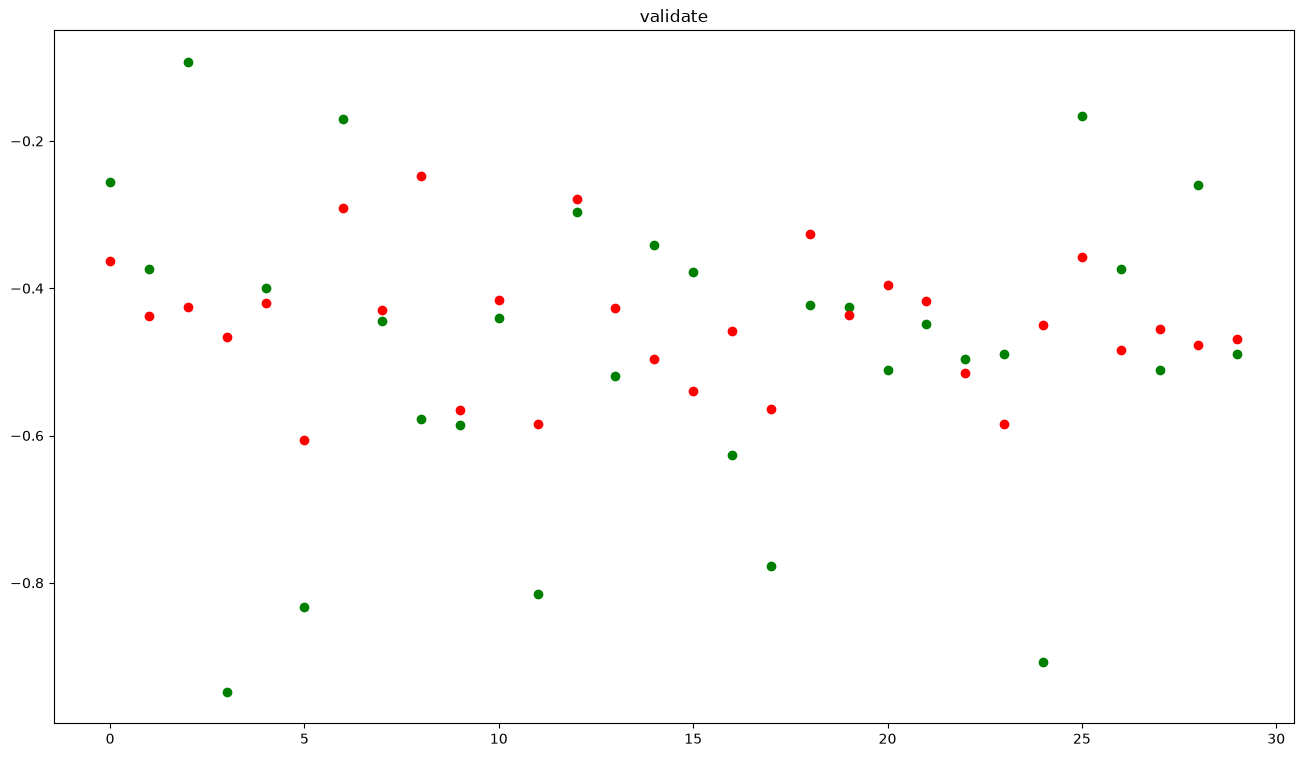

In [27]:
results=model.predict(x_val)
plt.scatter(range(len(y_val)),y_val,c='g')
plt.scatter(range(len(results)),results,c='r')
plt.title('validate')
plt.show()

In [28]:
ultimosDias = df['2018-11-16':'2018-11-30']
ultimosDias

,unidades
fecha,
2018-11-16,152
2018-11-17,111
2018-11-19,207
2018-11-20,206
2018-11-21,183
2018-11-22,200
2018-11-23,187
2018-11-24,189
2018-11-25,76


In [29]:
values = ultimosDias.values
values = values.astype('float32')
# normalize features
values=values.reshape(-1, 1) # esto lo hacemos porque tenemos 1 sola dimension
scaled = scaler.fit_transform(values)
reframed = series_to_supervised(scaled, PASOS, 1)
reframed.drop(reframed.columns[[7]], axis=1, inplace=True)
reframed.head(7)

,var1(t-7),var1(t-6),var1(t-5),var1(t-4),var1(t-3),var1(t-2),var1(t-1)
7,-0.24,-0.65,0.31,0.30,0.07,0.24,0.11
8,-0.65,0.31,0.30,0.07,0.24,0.11,0.13
9,0.31,0.30,0.07,0.24,0.11,0.13,-1.00
10,0.30,0.07,0.24,0.11,0.13,-1.00,1.00
11,0.07,0.24,0.11,0.13,-1.00,1.00,0.44
12,0.24,0.11,0.13,-1.00,1.00,0.44,0.07
13,0.11,0.13,-1.00,1.00,0.44,0.07,0.75


In [30]:
values = reframed.values
x_test = values[6:, :]
x_test = x_test.reshape((x_test.shape[0], 1, x_test.shape[1]))
x_test

array([[[ 0.11000001,  0.13      , -1.        ,  1.        ,
          0.44000006,  0.06999993,  0.75      ]]], dtype=float32)

In [32]:
def agregarNuevoValor(x_test,nuevoValor):
    for i in range(x_test.shape[2]-1):
        x_test[0][0][i] = x_test[0][0][i+1]
    x_test[0][0][x_test.shape[2]-1]=nuevoValor
    return x_test

results=[]
for i in range(7):
    parcial=model.predict(x_test)
    results.append(parcial[0])
    print(x_test)
    x_test = agregarNuevoValor(x_test, parcial[0].item())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
[[[ 0.13       -1.          1.          0.44000006  0.06999993
    0.75        0.75      ]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[[[-1.          1.          0.44000006  0.06999993  0.75
    0.75       -0.510735  ]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[[[ 1.          0.44000006  0.06999993  0.75        0.75
   -0.510735    0.38820976]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
[[[ 0.44000006  0.06999993  0.75        0.75       -0.510735
    0.38820976  0.4067587 ]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
[[[ 0.06999993  0.75        0.75       -0.510735    0.38820976
    0.4067587   0.14023681]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[[[ 0.75        0.75       -0.510735    0.38820976  0.4067587
    0.14023681  0.3085345 ]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
[[[ 0.75       -0.510735    0.38820976  0.4067587   0.14023681
    0.3085345   0.46375152]]]


In [33]:
adimen = [x for x in results]    
inverted = scaler.inverse_transform(adimen)
inverted

array([[124.9265043 ],
       [214.82097987],
       [216.67587347],
       [190.02368428],
       [206.85345397],
       [222.37515649],
       [152.31226576]])

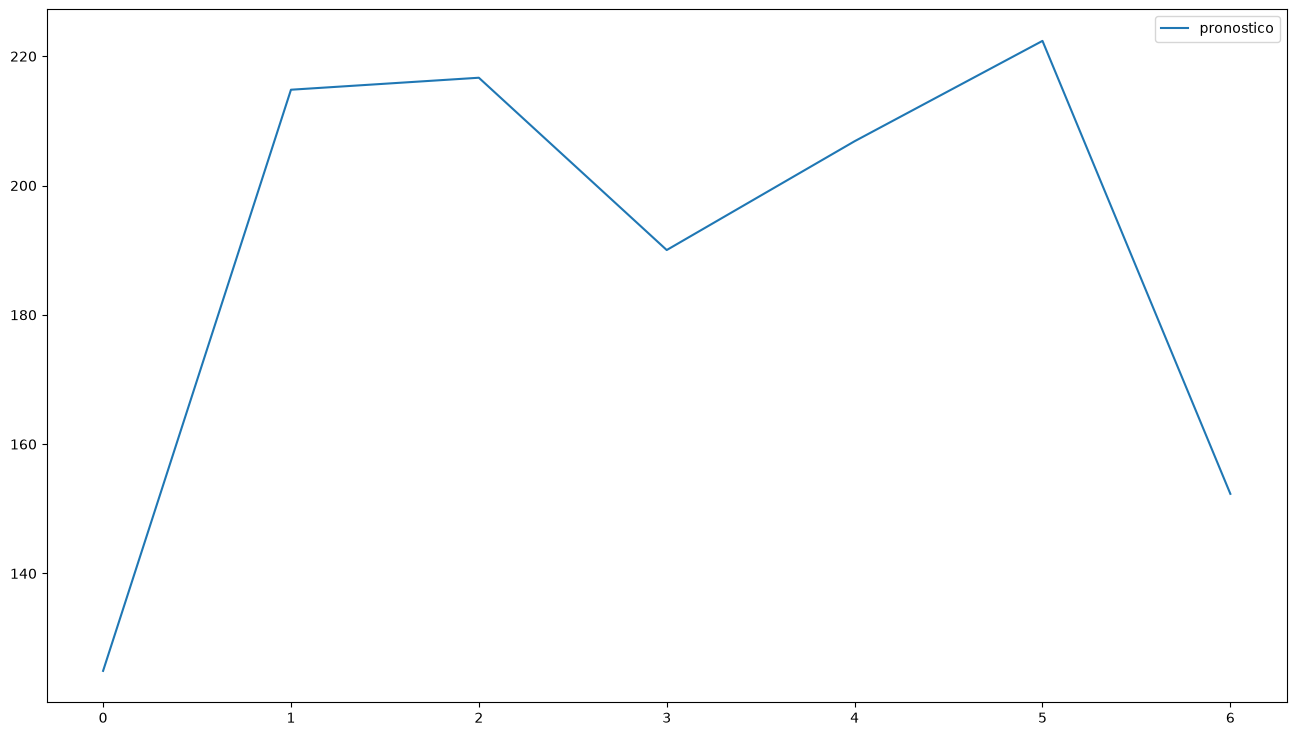

In [34]:
prediccion1SemanaDiciembre = pd.DataFrame(inverted)
prediccion1SemanaDiciembre.columns = ['pronostico']
prediccion1SemanaDiciembre.plot()
prediccion1SemanaDiciembre.to_csv('pronostico.csv')